# Setup

In [12]:
from dotenv import load_dotenv
import os
load_dotenv()

True

In [ ]:
os.getenv("GROQ_API_KEY")

In [5]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b")


In [15]:
res = llm.invoke("Hello")

In [16]:
print(res)

content='Hello! 👋 How can I assist you today?' additional_kwargs={'reasoning_content': 'We need to respond. The user just says "Hello". We should greet and ask how to help.'} response_metadata={'token_usage': {'completion_tokens': 42, 'prompt_tokens': 72, 'total_tokens': 114, 'completion_time': 0.049386498, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.004593982, 'prompt_tokens_details': None, 'queue_time': 0.306971914, 'total_time': 0.05398048}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_4f7e7dc26e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a1123d-0769-7763-958a-cc6746a8175e-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 72, 'output_tokens': 42, 'total_tokens': 114, 'output_token_details': {'reasoning': 22}}


In [19]:
print(res.content)

Hello! 👋 How can I assist you today?


# State - Global state to pass the data between all the nodes

In [20]:
from pydantic import BaseModel

class UserState(BaseModel):
    name: str = ""
    email: str = ""
    age: int = 0

## Building graph using Langgraph

In [21]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel

class MyState(BaseModel):
    messages: str = ""
    isPassed: bool = False

def greet(state: MyState):
    "I am a greeting Node...."
    state.isPassed = True
    state.messages = "Good Morning, How are you?"
    return state

graph = StateGraph(MyState)
graph.add_node("Welcome", greet)
graph.add_edge(START, "Welcome")
graph.add_edge("Welcome", END)

final_graph = graph.compile()

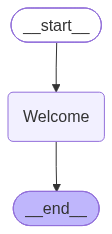

In [22]:
final_graph

In [23]:
res = final_graph.invoke({"messages": "hello"})

In [24]:
print(res)

{'messages': 'Good Morning, How are you?', 'isPassed': True}


## Multinode Graph

In [25]:
from random import randint

class ReviewState(BaseModel):
    text: str = ""
    score: int = 0
    comments: str = ""  

def score(state: ReviewState):
    "I am a scoring Node...."
    state.score = randint(1, 10)
    return state

def commenter(state: ReviewState):
    "I am a commenting Node...."
    if state.score > 5:
        state.comments = "Good Job!"
    else:
        state.comments = "Needs Improvement."
    return state

graph = StateGraph(ReviewState)
graph.add_node("score", score)
graph.add_node("commenter", commenter)

graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)

final_graph = graph.compile()

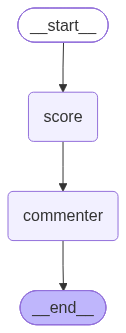

In [26]:
final_graph

In [31]:
res = final_graph.invoke({})

In [32]:
res

{'text': '', 'score': 10, 'comments': 'Good Job!'}

## add_messages reducer -> for chat history

In [33]:
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from typing import Annotated
from pydantic import BaseModel

def custom_reducer(existing: list, new: list):
    all_msgs = existing + new
    return all_msgs[-1:] # Keep only the last message

def isPositive(existing: list, new: list):
    if new < 0:
        return 0
    return new 

class chatState(BaseModel):
    messages: Annotated[list, custom_reducer] = []
    count: Annotated[int, isPositive] = 0

def chat_bot(state: chatState):
    state.messages = [llm.invoke(state.messages)]
    state.count -= 10
    return state

graph = StateGraph(chatState)

graph.add_node("chat_bot", chat_bot)

graph.add_edge(START, "chat_bot")   
graph.add_edge("chat_bot", END)

final_graph = graph.compile()



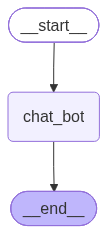

In [34]:
final_graph

In [35]:
res = final_graph.invoke({"messages": [HumanMessage(content="Hello, How are you?")]})

In [36]:
res

{'messages': [AIMessage(content='Hello! I’m doing great—thanks for asking. How about you? Anything new or interesting on your end?', additional_kwargs={'reasoning_content': 'We need to respond in a friendly manner. The user says "Hello, How are you?" We should greet back and ask about them. The user is asking how we are, so respond politely. No policy violation.'}, response_metadata={'token_usage': {'completion_tokens': 77, 'prompt_tokens': 77, 'total_tokens': 154, 'completion_time': 0.083101134, 'completion_tokens_details': {'reasoning_tokens': 45}, 'prompt_time': 0.09385844, 'prompt_tokens_details': None, 'queue_time': 0.38789629, 'total_time': 0.176959574}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8e23cedc90', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1123e-ad29-76e3-971e-38e00197e33f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens': 77, 'total_to

In [37]:
res["messages"][0].content

'Hello! I’m doing great—thanks for asking. How about you? Anything new or interesting on your end?'

## Routing - Langgraph core component

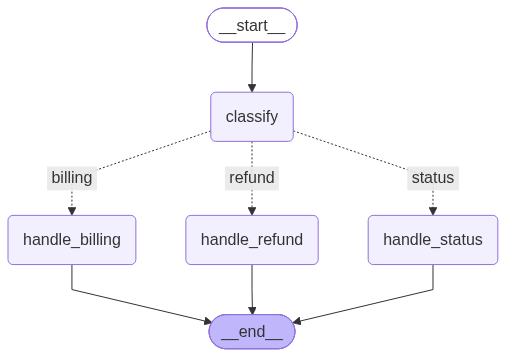

In [38]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Literal

class TicketState(BaseModel):
   issue: str = ""
   category: str = ""
   response: str = ""


def classify(state: TicketState) -> TicketState:
    issue = state.issue.lower()

    if "payment" in issue or "amount" in issue:
        state.category = "billing"
    elif "refund" in issue or "cancel" in issue:
        state.category = "refund"
    else:
        state.category = "status"

    return state


def handle_billing(state: TicketState) -> TicketState:
    print("Billing related issue...")
    state.response = f"Issue resolved for {state.category}"
    return state


def handle_refund(state: TicketState) -> TicketState:
    print("Refund related issue...")
    state.response = f"Issue resolved for {state.category}"
    return state

def handle_status(state: TicketState) -> TicketState:
    print("Status related issue...")
    state.response = f"Issue resolved for {state.category}"
    return state



def router_logic(state: TicketState) -> Literal["billing", "refund", "status"]:
    return state.category


graph = StateGraph(TicketState)

graph.add_node("classify", classify)
graph.add_node("handle_billing", handle_billing)
graph.add_node("handle_refund", handle_refund)
graph.add_node("handle_status", handle_status)

graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", router_logic,
                        {
                            "billing": "handle_billing",
                            "refund": "handle_refund",
                            "status": "handle_status"
                        }
                    )


graph.add_edge("handle_billing", END)
graph.add_edge("handle_refund", END)
graph.add_edge("handle_status", END)


final_graph = graph.compile()
final_graph



In [39]:
res = final_graph.invoke({"issue": "I want a refund for my last order."})

Refund related issue...


In [40]:
res = final_graph.invoke({"issue": "I want to get know payment information."})

Billing related issue...


## Memory - Checkpointer

In [41]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Annotated
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage

class chatState(BaseModel):
    messages: Annotated[list, add_messages]

def chat_bot(state: chatState):
    state.messages = [llm.invoke(state.messages)]
    return state

graph = StateGraph(chatState)

graph.add_node("chat_bot", chat_bot)

graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

memory = InMemorySaver()

final_graph = graph.compile(checkpointer=memory)



In [42]:
res = final_graph.invoke(
        {
            "messages": [HumanMessage(content="Who is the president of the India ?")]
        },
        {
            "configurable": {"thread_id": "thread_1"} 
        }
    )


ans = res["messages"][-1].content
print(ans)


The current President of India is **Draupadi Murmu**. She assumed office on 25 July 2022 and is the 15th person to hold the position.


In [43]:
res = final_graph.invoke(
        {
            "messages": [HumanMessage(content="How old is she?")]
        },
        {
            "configurable": {"thread_id": "thread_1"} 
        }
    )


ans = res["messages"][-1].content
print(ans)

Draupadi Murmu was born on **15 November 1958**.  
As of today (6 October 2026) she is **67 years old**—she will turn 68 in a little over a month.


In [44]:
res = final_graph.invoke(
        {
            "messages": [HumanMessage(content="How old is she?")]
        },
        {
            "configurable": {"thread_id": "thread_2"}  # thread_id changed, context no longer available
        }
    )


ans = res["messages"][-1].content
print(ans)

I’m not sure who you’re referring to. Could you let me know which person you’re asking about?


In [45]:
%pip install langgraph checkpointer-sqlite

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement checkpointer-sqlite (from versions: none)
ERROR: No matching distribution found for checkpointer-sqlite

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

connection = sqlite3.connect("sqlite3.db", check_same_thread=False)
sql_memory = SqliteSaver(connection)
sql_memory.setup()

In [8]:
sqlite_graph = graph.compile(checkpointer=sql_memory)

In [48]:
res = sqlite_graph.invoke(
    {
        "messages": [HumanMessage(content="Who is the known as the missile man of India?")]
    },
    {
        "configurable": {"thread_id": "thread_2"}
    }
)

ans = res["messages"][-1].content
print(ans)


The “Missile Man of India” is **Dr. A.P.J. Abdul Kalam**.


In [49]:
res = sqlite_graph.invoke(
    {
        "messages": [HumanMessage(content="Why was he known with that name?")]
    },
    {
        "configurable": {"thread_id": "thread_2"}
    }
)

ans = res["messages"][-1].content
print(ans)

### Why Dr. A.P.J. Abdul Kalam earned the title **“Missile Man of India”**

| Key Contribution | What it meant | How it earned the nickname |
|------------------|---------------|---------------------------|
| **Head of the Integrated Guided Missile Development Programme (IGMDP)** | IGMDP was India’s flagship project to build indigenous ballistic missiles (Prithvi, Agni). | Kalam was the scientific architect behind the programme’s success, making him the face of India’s missile capability. |
| **First successful Agni‑I test (1984)** | Demonstrated that India could build and fire an inter‑continental ballistic missile (ICBM). | The press and the public began linking his name with this historic breakthrough. |
| **Agni‑III and Prithvi‑II tests (1999)** | Expanded India’s range and strike options, cementing strategic deterrence. | These milestones reinforced his image as the chief driver of India’s missile technology. |
| **Adaptation of missile tech for space launch vehicles (Vikram‑V/GSL

## Agents and Tools - ToolNodes


In [50]:
%pip show langchain langgraph langchain-core

Name: langchain
Version: 1.4.3
Summary: Building applications with LLMs through composability
Home-page: 
Author: 
Author-email: 
License: MIT
Location: c:\Users\Sarthak jain\AppData\Local\Programs\Python\Python311\Lib\site-packages
Requires: langchain-core, langgraph, pydantic
Required-by: 
---
Name: langgraph
Version: 1.2.13
Summary: Building stateful, multi-actor applications with LLMs
Home-page: 
Author: 
Author-email: 
License: 
Location: c:\Users\Sarthak jain\AppData\Local\Programs\Python\Python311\Lib\site-packages
Requires: langchain-core, langgraph-checkpoint, langgraph-prebuilt, langgraph-sdk, pydantic, xxhash
Required-by: langchain
---
Name: langchain-core
Version: 1.6.6
Summary: Building applications with LLMs through composability
Home-page: 
Author: 
Author-email: 
License: MIT
Location: c:\Users\Sarthak jain\AppData\Local\Programs\Python\Python311\Lib\site-packages
Requires: httpx, jsonpatch, langchain-protocol, langsmith, packaging, pydantic, pyyaml, tenacity, typing-ex

In [1]:
import sys
print(sys.executable)

c:\Users\Sarthak jain\Langgraph Concepts\.venv\Scripts\python.exe


In [3]:
from langchain.tools import tool

@tool
def weather_tool(city: str) -> str:
    """Get the current weather for a given city."""
    return f"The current weather in {city} is sunny with a temperature of 25°C."

@tool
def calculate(expression: str) -> str:
    """Evaluate a mathematical expression."""
    try:
        result = eval(expression)
        return f"The result of '{expression}' is {result}."
    except Exception as e:
        return f"Error evaluating expression: {e}"




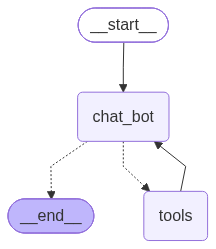

In [9]:
from pydantic import BaseModel
from typing import Annotated
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import tools_condition, ToolNode


class AgentState(BaseModel):
    messages: Annotated[list, add_messages]

tools = [weather_tool, calculate]
llm_with_tools = llm.bind_tools(tools)

def chat_bot(state: AgentState):
    res = llm_with_tools.invoke(state.messages)
    state.messages = [res]
    return state

tool_node = ToolNode(tools)

graph = StateGraph(AgentState)
graph.add_node("chat_bot", chat_bot)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat_bot")
graph.add_conditional_edges("chat_bot", tools_condition)
graph.add_edge("tools", "chat_bot")
graph.add_edge("chat_bot", END)

final_graph = graph.compile(checkpointer=sql_memory)
final_graph



In [11]:
res = final_graph.invoke(
    {
        "messages": [HumanMessage(content="What is the temperature in Bhopal?")]
    },
    {
        "configurable":{"thread_id": "thread_5"}
    }
)

ans = res["messages"][-1].content

In [12]:
ans

'The temperature in Bhopal is **25\u202f°C**.'

In [ ]:
res = final_graph.invoke(
    {
        "messages": [HumanMessage(content="What is the 2 + 2")]
    },
    {
        "configurable":{"thread_id": "thread_6"}
    }
)

ans = res["messages"]

In [18]:
ans

[HumanMessage(content='What is the 2 + 2', additional_kwargs={}, response_metadata={}, id='e6d95908-c0dd-47ae-9099-92a53f810b2f'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "What is the 2 + 2". They want calculation. Use calculate tool.', 'tool_calls': [{'id': 'fc_3ed137e5-5a88-4536-9648-c501b28777a6', 'function': {'arguments': '{"expression":"2+2"}', 'name': 'calculate'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 149, 'total_tokens': 195, 'completion_time': 0.053076556, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.008675263, 'prompt_tokens_details': None, 'queue_time': 0.344824723, 'total_time': 0.061751819}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_996f667773', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1125f-34c1-77c3-8d25-999706a4f70d-0', tool_calls=[{'name': 'calculate

## Human In the Loop

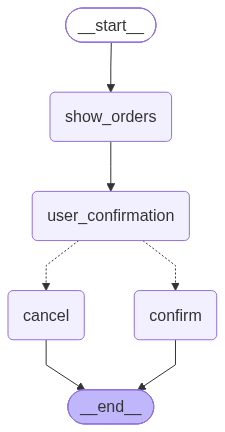

In [21]:
from pydantic import BaseModel
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

class PurchaseState(BaseModel):
    item: str = ""
    price: int = 0
    confirmed: bool = False
    status: str = ""

def show_orders(state: PurchaseState) -> PurchaseState:
    print(f"Order summary: Product: {state.item}, Price: {state.price}")
    return state

def user_confirmation(state: PurchaseState) -> PurchaseState:
    response = interrupt(
        {

            "question": f"Confirm your purchase for {state.item} and price is {state.price}. Please reply in yes or no"
        }
    )

    state.confirmed = response.lower() == "yes"
    return state

def order_cancel(state: PurchaseState) -> PurchaseState:
    print("We have cancelled your order. Thanks!")
    return state

def order_confirm(state: PurchaseState) -> PurchaseState:
    print("You successfully placed your order...")
    return state

def router(state: PurchaseState) -> Literal["cancel", "confirm"]:
    if state.confirmed:
        return "confirm"
    return "cancel"


graph = StateGraph(PurchaseState)

graph.add_node("show_orders", show_orders)
graph.add_node("user_confirmation", user_confirmation)
graph.add_node("cancel", order_cancel)
graph.add_node("confirm", order_confirm)


graph.add_edge(START, "show_orders")
graph.add_edge("show_orders", "user_confirmation")
graph.add_conditional_edges("user_confirmation", router)
graph.add_edge("cancel", END)
graph.add_edge("confirm", END)


final_graph = graph.compile(checkpointer=InMemorySaver())

final_graph


In [30]:
res = final_graph.invoke(
    {
        "item": "Samsung S26",
        "price": 125000
    },
    {
        "configurable": {"thread_id": "thread_6"}
    }
)

print(res["__interrupt__"][0].value["question"])

Order summary: Product: Samsung S26, Price: 125000
Confirm your purchase for Samsung S26 and price is 125000. Please reply in yes or no


In [31]:
res = final_graph.invoke(
    Command(resume="yes"),
    {
        "configurable": {"thread_id": "thread_6"}
    }
)

print(res)

You successfully placed your order...
{'item': 'Samsung S26', 'price': 125000, 'confirmed': True, 'status': ''}


In [32]:
res = final_graph.invoke(
    Command(resume="no"),
    {
        "configurable": {"thread_id": "thread_7"}
    }
)

print(res)

{'item': 'Samsung S26', 'price': 125000, 'confirmed': False, 'status': ''}


## Parallel Operations: Nodes

In [33]:
DOCUMENTS = [
    {"id": 1, "text": "LangGraph is a library for building stateful, multi-actor applications with LLMs."},
    {"id": 2, "text": "Python is a high-level programming language known for its simple syntax and readability."},
    {"id": 3, "text": "Machine learning enables systems to learn from data automatically."},
]

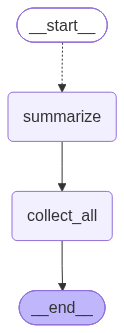

In [41]:
import operator
from datetime import datetime
from typing import Annotated
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send, Overwrite


def custom_reducer(existing: list, new: list):
    return existing + new


class SummarizerState(BaseModel):
    documents: list[dict] = []
    summaries: Annotated[list, custom_reducer]

class Document(BaseModel):
    id: int = 0
    text: str = ""


def route_to_summarizer(state: SummarizerState):
    sends = []
    for doc in state.documents:
        document = Document(id = doc["id"], text=doc["text"])
        sends.append(Send("summarize", document))

    return sends


def summarize(state: Document):
    now = datetime.now()
    print("\n Summarize Node...", now.strftime("%M:%S"))
    response = llm.invoke(f"Summarize in 5 words: {state.text}")
    return {"summaries": [{"id": state.id, "summary": response.content.strip() }]}



def collect_all(state: SummarizerState):
    print("All Summaries: ", state.summaries)
    return {}



graph = StateGraph(SummarizerState)

graph.add_node("summarize", summarize)
graph.add_node("collect_all", collect_all)

graph.add_conditional_edges(START, route_to_summarizer, ["summarize"])
graph.add_edge("summarize", "collect_all")
graph.add_edge("collect_all", END)


final_graph = graph.compile(checkpointer=InMemorySaver())

final_graph



In [42]:
res = final_graph.invoke({"documents": DOCUMENTS, "summaries": Overwrite([])}, {"configurable": {"thread_id":"thread_10"}})


 Summarize Node... 14:16

 Summarize Node... 14:16

 Summarize Node... 14:16
All Summaries:  [{'id': 1, 'summary': 'LangGraph builds multi‑actor LLM applications.'}, {'id': 2, 'summary': 'Python: simple, readable, high-level language.'}, {'id': 3, 'summary': 'ML lets systems learn automatically.'}]
